<a href="https://colab.research.google.com/github/jessicarmagalhaes21-png/Informatica_Aplicada/blob/main/Regressaolinearestudoxnota.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

# URL original do GitHub convertida para o formato Raw para que o pandas possa ler diretamente
url = 'https://raw.githubusercontent.com/Sainathmudigonda/Student-Result-Analysis/main/student_exam_scores.csv'

# Lendo o arquivo CSV
df = pd.read_csv(url)

# Exibindo as primeiras linhas do DataFrame
display(df.head())

,student_id,hours_studied,sleep_hours,attendance_percent,previous_scores,exam_score
0,S001,8.0,8.8,72.1,45,30.2
1,S002,1.3,8.6,60.7,55,25.0
2,S003,4.0,8.2,73.7,86,35.8
3,S004,3.5,4.8,95.1,66,34.0
4,S005,9.1,6.4,89.8,71,40.3


### Criando o Modelo de Regressão Linear

Vamos dividir o conjunto de dados em variáveis independentes (preditoras) e dependente (alvo), separar em dados de treino e teste, ajustar o modelo de regressão linear e avaliar sua performance.

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Definindo as variáveis preditoras (X) e a variável alvo (y)
# Removemos o 'student_id' pois é apenas um identificador único
X = df[['hours_studied', 'sleep_hours', 'attendance_percent', 'previous_scores']]
y = df['exam_score']

# Dividindo os dados em conjuntos de treino (80%) e teste (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Inicializando e treinando o modelo de Regressão Linear
model = LinearRegression()
model.fit(X_train, y_train)

# Realizando predições no conjunto de teste
y_pred = model.predict(X_test)

# Avaliando o modelo
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("=== Métricas de Avaliação do Modelo ===")
print(f"R² Score: {r2:.4f}")
print(f"Erro Quadrático Médio (MSE): {mse:.4f}")
print(f"Raiz do Erro Quadrático Médio (RMSE): {rmse:.4f}")

# Exibindo os coeficientes das variáveis
print("\n=== Coeficientes do Modelo ===")
for col, coef in zip(X.columns, model.coef_):
    print(f"{col}: {coef:.4f}")
print(f"Intercepto: {model.intercept_:.4f}")

=== Métricas de Avaliação do Modelo ===
R² Score: 0.8537
Erro Quadrático Médio (MSE): 7.7618
Raiz do Erro Quadrático Médio (RMSE): 2.7860

=== Coeficientes do Modelo ===
hours_studied: 1.5493
sleep_hours: 0.8842
attendance_percent: 0.1089
previous_scores: 0.1830
Intercepto: -2.2050


In [3]:
# Criando um DataFrame comparativo entre os valores reais e as predições
comparativo = pd.DataFrame({
    'Valor Real': y_test,
    'Valor Predito': y_pred,
    'Diferença (Resíduo)': y_test - y_pred
})

display(comparativo.head(10))

,Valor Real,Valor Predito,Diferença (Resíduo)
95,28.7,28.886072,-0.186072
15,34.1,29.680421,4.419579
30,34.5,35.311956,-0.811956
158,29.5,31.180448,-1.680448
128,36.1,39.448943,-3.348943
115,46.4,41.691583,4.708417
69,23.9,23.969183,-0.069183
170,45.3,45.722509,-0.422509
174,44.8,41.652932,3.147068
45,31.8,27.476157,4.323843


### Regressão Linear Simples: Horas de Estudo vs Nota da Prova

Agora vamos construir o modelo considerando apenas uma única variável preditora:
* **X**: `hours_studied` (Horas de Estudo)
* **y**: `exam_score` (Nota da Prova)

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np
import matplotlib.pyplot as plt

# Definindo X (horas de estudo) e y (nota da prova)
# Precisamos remodelar X para ser uma matriz 2D pois possui apenas uma característica
X_simples = df[['hours_studied']]
y_simples = df['exam_score']

# Dividindo em treino (80%) e teste (20%)
X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(X_simples, y_simples, test_size=0.2, random_state=42)

# Inicializando e treinando o modelo
model_simples = LinearRegression()
model_simples.fit(X_train_s, y_train_s)

# Predições
y_pred_s = model_simples.predict(X_test_s)

# Avaliando as métricas
mse_s = mean_squared_error(y_test_s, y_pred_s)
rmse_s = np.sqrt(mse_s)
r2_s = r2_score(y_test_s, y_pred_s)

print("=== Métricas do Modelo Simples ===")
print(f"R² Score: {r2_s:.4f}")
print(f"RMSE: {rmse_s:.4f}")
print(f"Coeficiente (Inclinação): {model_simples.coef_[0]:.4f}")
print(f"Intercepto: {model_simples.intercept_:.4f}")

=== Métricas do Modelo Simples ===
R² Score: 0.6389
RMSE: 4.3775
Coeficiente (Inclinação): 1.6146
Intercepto: 23.7840


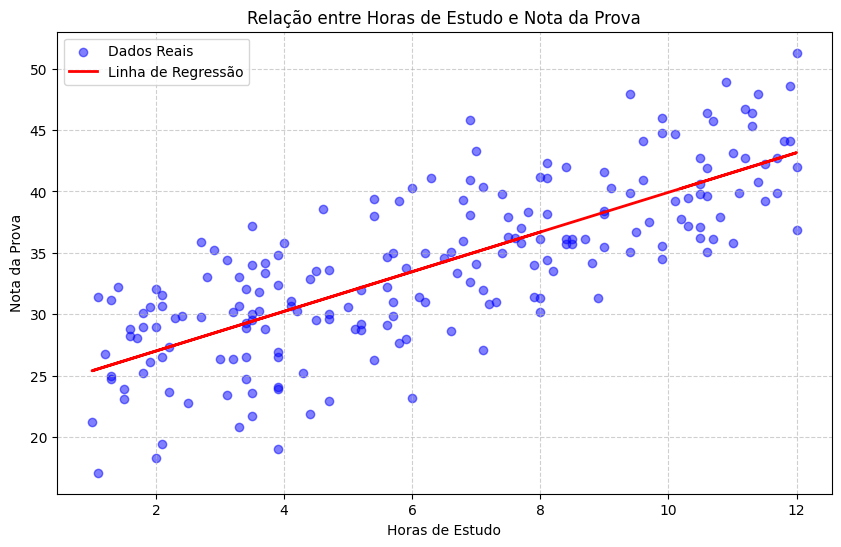

In [5]:
# Visualizando a reta de regressão com Matplotlib
plt.figure(figsize=(10, 6))
plt.scatter(X_simples, y_simples, color='blue', alpha=0.5, label='Dados Reais')
plt.plot(X_simples, model_simples.predict(X_simples), color='red', linewidth=2, label='Linha de Regressão')
plt.title('Relação entre Horas de Estudo e Nota da Prova')
plt.xlabel('Horas de Estudo')
plt.ylabel('Nota da Prova')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()